In [1]:
import pandas as pd
import numpy as np

# Load cleaned dataset
df = pd.read_csv("GE_OE_Cleaned_Data.csv")
print(df)

             Timestamp 3) What is your gender?  \
0   8/19/2026 10:57:56                    Male   
1    8/30/2026 7:55:20                    Male   
2    8/30/2026 9:28:03                    Male   
3   8/30/2026 10:11:59                    Male   
4   8/30/2026 10:32:12                    Male   
..                 ...                     ...   
87   9/8/2026 21:23:20                    Male   
88   9/8/2026 22:21:36                    Male   
89   9/8/2026 23:52:38                    Male   
90   9/9/2026 12:02:56                    Male   
91   9/9/2026 12:19:46                  Female   

   4) Which course/program are you studying?  \
0                                       B.SC   
1                                       B.SC   
2                                       B.SC   
3                                       B.SC   
4                                       B.SC   
..                                       ...   
87                                       B.A   
88             

In [5]:
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder

# Encode input features
encoder3 = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X3_encoded = pd.DataFrame(
    encoder3.fit_transform(X3),
    columns=X3.columns,
    index=X3.index
)

# Encode target
label_encoder3 = LabelEncoder()
y3_encoded = label_encoder3.fit_transform(y3)

print("Input shape:", X3_encoded.shape)
print("Target shape:", y3_encoded.shape)
print("Target classes:", label_encoder3.classes_)

Input shape: (88, 23)
Target shape: (88,)
Target classes: ['Moderately' 'Not At All' 'Significantly' 'Slightly']


In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create and train the model
model3 = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=3,
    random_state=42
)

model3.fit(X_train3, y_train3)

# Make predictions
y_pred3 = model3.predict(X_test3)

# Calculate accuracy
accuracy3 = accuracy_score(y_test3, y_pred3)

print("Decision Tree Accuracy:", round(accuracy3 * 100, 2), "%")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test3, y_pred3))

print("\nClassification Report:")
print(classification_report(
    y_test3,
    y_pred3,
    target_names=label_encoder3.classes_,
    zero_division=0
))

Decision Tree Accuracy: 44.44 %

Confusion Matrix:
[[6 1 0 4]
 [1 1 1 1]
 [3 0 3 1]
 [2 0 1 2]]

Classification Report:
               precision    recall  f1-score   support

   Moderately       0.50      0.55      0.52        11
   Not At All       0.50      0.25      0.33         4
Significantly       0.60      0.43      0.50         7
     Slightly       0.25      0.40      0.31         5

     accuracy                           0.44        27
    macro avg       0.46      0.41      0.42        27
 weighted avg       0.48      0.44      0.45        27



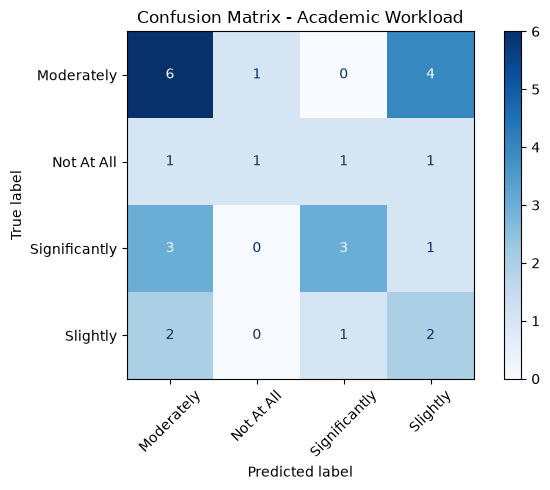

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm3 = confusion_matrix(y_test3, y_pred3)

fig, ax = plt.subplots(figsize=(7, 5))

disp3 = ConfusionMatrixDisplay(
    confusion_matrix=cm3,
    display_labels=label_encoder3.classes_
)

disp3.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Confusion Matrix - Academic Workload")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
target_col3 = [
    col for col in df.columns
    if "increase your academic workload" in col.lower()
][0]

print("Target Column:", target_col3)
print(df[target_col3].value_counts())

Target Column: 12)  Do  GE/OE  subjects increase your academic workload?  
12)  Do  GE/OE  subjects increase your academic workload?  
Moderately       35
Significantly    23
Slightly         18
Not At All       12
Not Answered      4
Name: count, dtype: int64


In [14]:
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
import pandas as pd

df_ml3 = df[
    df[target_col3].notna() &
    (df[target_col3] != "Not Answered")
].copy()

y3 = df_ml3[target_col3]
X3 = df_ml3.drop(
    columns=[target_col3, "Timestamp"],
    errors="ignore"
)

encoder3 = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X3_encoded = pd.DataFrame(
    encoder3.fit_transform(X3),
    columns=X3.columns,
    index=X3.index
)

label_encoder3 = LabelEncoder()
y3_encoded = label_encoder3.fit_transform(y3)

X_train3, X_test3, y_train3, y_test3 = train_test_split(
    X3_encoded,
    y3_encoded,
    test_size=0.3,
    random_state=42,
    stratify=y3_encoded
)

imputer3 = SimpleImputer(strategy="most_frequent")

X_train3 = pd.DataFrame(
    imputer3.fit_transform(X_train3),
    columns=X_train3.columns,
    index=X_train3.index
)

X_test3 = pd.DataFrame(
    imputer3.transform(X_test3),
    columns=X_test3.columns,
    index=X_test3.index
)

print("Training Data:", X_train3.shape)
print("Testing Data:", X_test3.shape)

Training Data: (61, 23)
Testing Data: (27, 23)


In [15]:
from sklearn.tree import DecisionTreeClassifier

model3 = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=3,
    random_state=42
)

model3.fit(X_train3, y_train3)

y_pred3 = model3.predict(X_test3)

print("Decision Tree Model Trained Successfully")

Decision Tree Model Trained Successfully


In [21]:
results_actual3 = pd.DataFrame({
    "Actual": label_encoder3.inverse_transform(y_test3),
    "Predicted": label_encoder3.inverse_transform(y_pred3)
})

results_actual3.index = range(1, len(results_actual3) + 1)
results_actual3.index.name = "Index"

display(results_actual3)

,Actual,Predicted
Index,,
1,Significantly,Moderately
2,Moderately,Not At All
3,Moderately,Moderately
4,Significantly,Significantly
5,Slightly,Significantly
6,Not At All,Moderately
7,Moderately,Slightly
8,Slightly,Moderately
9,Significantly,Significantly


In [17]:
from sklearn.metrics import accuracy_score, classification_report

accuracy3 = accuracy_score(y_test3, y_pred3)

print("Decision Tree Accuracy:", round(accuracy3 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test3,
    y_pred3,
    labels=range(len(label_encoder3.classes_)),
    target_names=label_encoder3.classes_,
    zero_division=0
))

Decision Tree Accuracy: 44.44 %

Classification Report:
               precision    recall  f1-score   support

   Moderately       0.50      0.55      0.52        11
   Not At All       0.50      0.25      0.33         4
Significantly       0.60      0.43      0.50         7
     Slightly       0.25      0.40      0.31         5

     accuracy                           0.44        27
    macro avg       0.46      0.41      0.42        27
 weighted avg       0.48      0.44      0.45        27



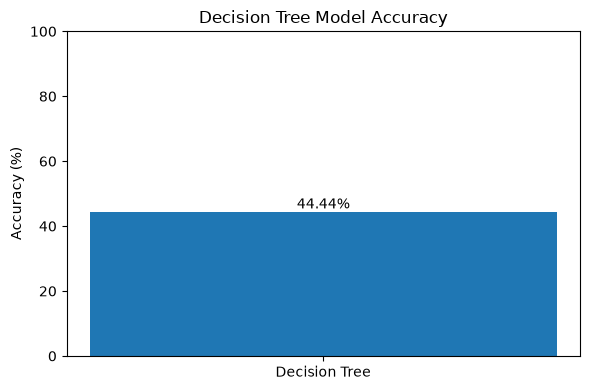

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
bars = plt.bar(["Decision Tree"], [accuracy3 * 100])

plt.title("Decision Tree Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.text(
    0,
    accuracy3 * 100 + 1,
    f"{accuracy3 * 100:.2f}%",
    ha="center"
)

plt.tight_layout()
plt.show()

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models3 = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "SVM": SVC()
}

model_names3 = []
accuracies3 = []

for name, model in models3.items():
    model.fit(X_train3, y_train3)
    predictions = model.predict(X_test3)

    model_names3.append(name)
    accuracies3.append(
        accuracy_score(y_test3, predictions) * 100
    )

comparison_df3 = pd.DataFrame({
    "Model": model_names3,
    "Accuracy (%)": [round(a, 2) for a in accuracies3]
})

print(comparison_df3.to_string(index=False))

        Model  Accuracy (%)
Decision Tree         44.44
Random Forest         55.56
          SVM         40.74


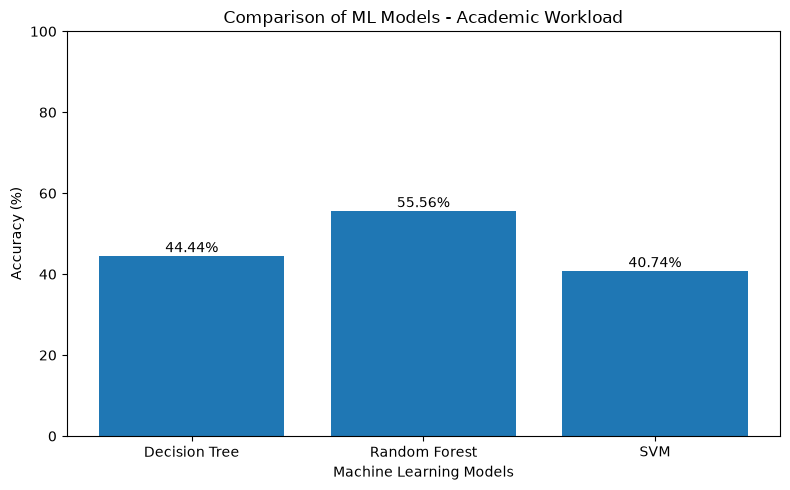

In [20]:
plt.figure(figsize=(8, 5))

bars = plt.bar(model_names3, accuracies3)

plt.title("Comparison of ML Models - Academic Workload")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, accuracies3):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()